In [6]:
import sys
import numpy as np

sys.path.append("../src")

from data_processing.load import load_and_preprocess_data
from models.model import WindPowerQuantile

import jax.numpy as jnp

import torch
from torch import nn, optim
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

### Load data and preprocess

- wind direction transformed from degree using sin and cos
- select one bid zone
- include UMM downtime data
- calculate capacity factor
- scale input features and meta data

Shapes:

- X: (timestamps, wind parks, features)
- Y: (timestamps)
- sites_meta: (wind parks, 1)


In [2]:
from operator import itemgetter

data = load_and_preprocess_data()
(
    X_train,
    X_test,
    Y_train_gen,
    Y_test_gen,
    Y_train_cf,
    Y_test_cf,
    Y_train_aval,
    Y_test_aval,
    sites_meta,
    feature_cols,
) = itemgetter(
    "X_train",
    "X_test",
    "Y_train_gen",
    "Y_test_gen",
    "Y_train_cf",
    "Y_test_cf",
    "Y_train_aval",
    "Y_test_aval",
    "sites_meta",
    "feature_cols",
)(
    data
)

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Preprocessing done. X_train shape: (19130, 6, 6)
Preprocessing done. X_test shape: (2161, 6, 6)


### Deterministic Quantile NN

- Shared weights for all parks -> sum over parks
- Predicts Quantiles to approximate the full CDF
- Median acts as an anchor
- Distances to median for other quantiles
- All distances are generated by softplus -> positive -> ordering guaranteed and no crossing


In [3]:
X_train_tensor = torch.tensor(X_train)
Y_train_cf_tensor = torch.tensor(Y_train_cf)
Y_train_gen_tensor = torch.tensor(Y_train_gen)
X_test_tensor = torch.tensor(X_test)
Y_test_cf_tensor = torch.tensor(Y_test_cf)
sites_meta_tensor = torch.tensor(sites_meta, dtype=torch.float32)

In [4]:
_, num_windparks, num_features = X_train_tensor.shape

In [7]:
def quantile_loss(preds, target, quantiles=(0.025, 0.5, 0.975)):
    # preds: [T, Q], target: [T]
    diff = target.unsqueeze(-1) - preds  # [T, Q]
    quantiles = torch.tensor(quantiles).to(preds.device)  # [Q]

    # Pinball loss:
    loss = torch.maximum(quantiles * diff, (quantiles - 1) * diff)
    return loss.mean()

In [8]:
quantiles = np.linspace(0, 1, 51)
nn_model_quantile = WindPowerQuantile(num_features, quantiles)
optimizer = optim.Adam(nn_model_quantile.parameters(), lr=1e-3)
criterion = lambda preds, target: quantile_loss(preds, target, quantiles=quantiles)

losses = []

for step in range(3000):
    nn_model_quantile.train()
    optimizer.zero_grad()
    y_sum_pred = nn_model_quantile(X_train_tensor)

    loss = criterion(y_sum_pred, Y_train_gen_tensor)
    losses.append(loss.item())

    loss.backward()
    optimizer.step()

    if step % 250 == 0:
        print(f"Step {step:3d} | Loss: {loss.item():.4f}")

Step   0 | Loss: 51.1893
Step 250 | Loss: 17.6921
Step 500 | Loss: 13.8807
Step 750 | Loss: 13.2461
Step 1000 | Loss: 12.8898
Step 1250 | Loss: 12.6138
Step 1500 | Loss: 12.3961
Step 1750 | Loss: 12.2143
Step 2000 | Loss: 12.0593
Step 2250 | Loss: 11.9322
Step 2500 | Loss: 11.8225
Step 2750 | Loss: 11.7369


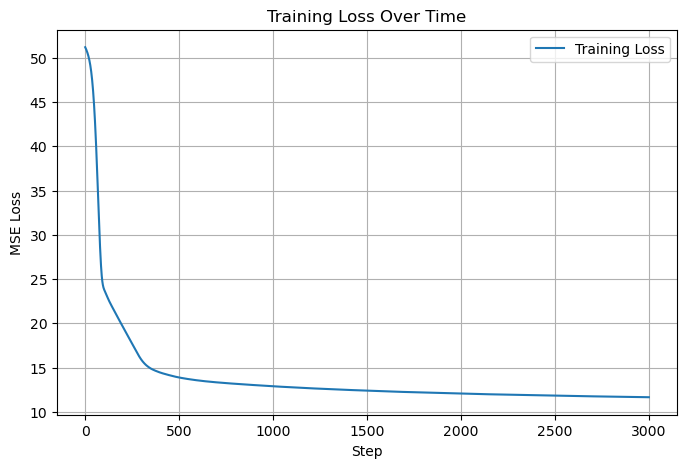

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(losses, label="Training Loss")
plt.xlabel("Step")
plt.ylabel("MSE Loss")
plt.title("Training Loss Over Time")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
median_idx = (quantiles == 0.5).nonzero()[0].item()

nn_model_quantile.eval()
with torch.no_grad():
    y_sum_pred = nn_model_quantile(X_test_tensor)

Y_pred = y_sum_pred.numpy()

mse = mean_squared_error(Y_test_gen, Y_pred[:, median_idx])
rmse = jnp.sqrt(mse)


print(f"Evaluation metrics:")
print(f"RMSE: {rmse:.2f} MW")

Evaluation metrics:
RMSE: 64.34 MW


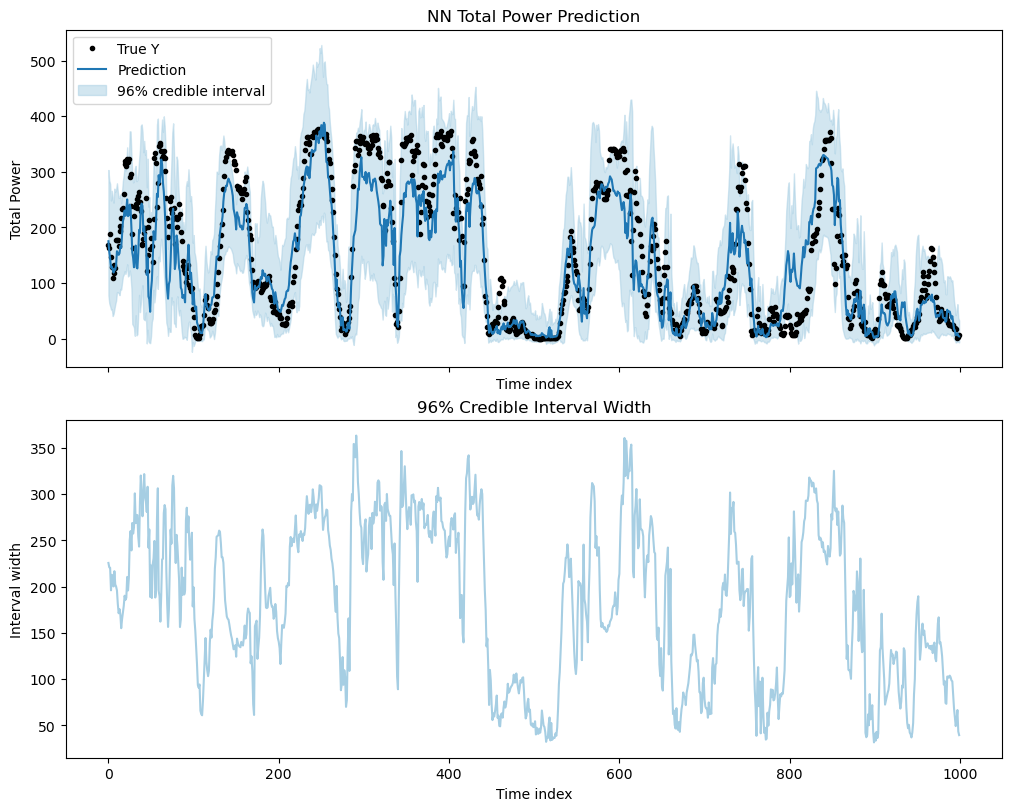

In [18]:
# Plot
median_idx = (quantiles == 0.5).nonzero()[0].item()
q025_idx = (quantiles == 0.02).nonzero()[0].item()
q975_idx = (quantiles == 0.98).nonzero()[0].item()

n_plot = 1000
fig, axes = plt.subplots(figsize=(10, 8), nrows=2, sharex=True, constrained_layout=True)
ax = axes[0]
ax.plot(Y_test_gen[:n_plot], ".", color="black", label="True Y")
ax.plot(Y_pred[:n_plot, median_idx], color="C0", label="Prediction")
ax.fill_between(
    range(n_plot),
    Y_pred[:n_plot, q025_idx],
    Y_pred[:n_plot, q975_idx],
    color="#A6CEE3",
    alpha=0.5,
    label="96% credible interval",
)
ax.set(xlabel="Time index", ylabel="Total Power", title="NN Total Power Prediction")
ax.legend()

ax2 = axes[1]
ax2.plot(
    range(n_plot),
    Y_pred[:n_plot, q975_idx] - Y_pred[:n_plot, q025_idx],
    color="#A6CEE3",
)
ax2.set(
    xlabel="Time index",
    ylabel="Interval width",
    title="96% Credible Interval Width",
)
plt.show()

### Sanity checks


In [19]:
violations = np.mean(np.diff(Y_pred, axis=1) < 0)
print("Fraction of quantile crossing violations:", violations)

Fraction of quantile crossing violations: 0.0


In [20]:
emp_cov = [np.mean(Y_test_gen <= Y_pred[:, i]) for i in range(len(quantiles))]

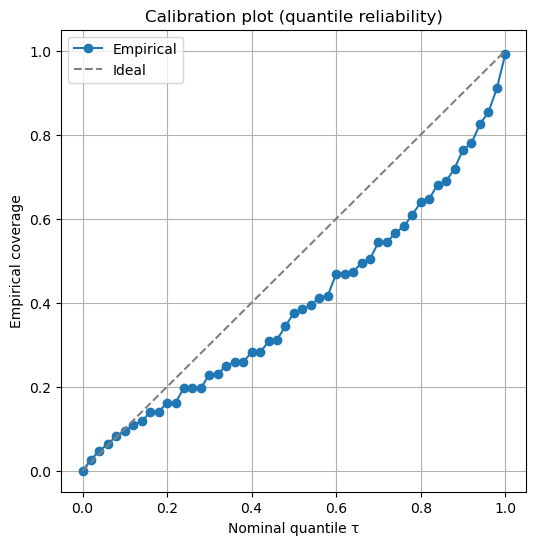

In [21]:
plt.figure(figsize=(6, 6))
plt.plot(quantiles, emp_cov, "o-", label="Empirical")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Ideal")
plt.xlabel("Nominal quantile τ")
plt.ylabel("Empirical coverage")
plt.title("Calibration plot (quantile reliability)")
plt.legend()
plt.grid(True)
plt.show()

In [22]:
q_low = Y_pred[:, q025_idx]
q_high = Y_pred[:, q975_idx]
inside = np.mean((Y_test_gen >= q_low) & (Y_test_gen <= q_high))
print("96% interval empirical coverage:", inside)

96% interval empirical coverage: 0.8838500694123091


In [23]:
coverages = []

for j, tau in enumerate([0.02, 0.5, 0.98]):
    idx = (quantiles == tau).nonzero()[0].item()
    cov = np.mean(Y_test_gen <= Y_pred[:, idx])
    coverages.append(cov)
    print(f"Quantile τ={tau:.3f}, empirical P(Y ≤ q_τ) = {cov:.3f}")

Quantile τ=0.020, empirical P(Y ≤ q_τ) = 0.026
Quantile τ=0.500, empirical P(Y ≤ q_τ) = 0.376
Quantile τ=0.980, empirical P(Y ≤ q_τ) = 0.910


### Approximation of CDF and PDF

- with enough quantiles, the CDF can be approximated empirically


In [124]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde


class QuantileDistribution:
    """
    A utility class that converts model-predicted quantiles q(τ)
    into a full predictive distribution with:
        - inverse CDF
        - CDF
        - PDF (via dq/dτ)
        - sampling
        - highest-density intervals (HDIs)
        - KDE-based PDF for smoothing
        - plotting utilities
    """

    def __init__(self, quantile_levels, quantile_values, eps=1e-6):
        self.taus = np.asarray(quantile_levels)
        self.qvals = np.asarray(quantile_values)
        self.eps = eps

        # Sort to ensure correct order
        idx = np.argsort(self.taus)
        self.taus = self.taus[idx]
        self.qvals = self.qvals[idx]

        assert len(self.taus) == len(self.qvals), "taus and qvals must have same length"

        # Enforce monotonicity (usually already guaranteed by model)
        self.qvals = np.maximum.accumulate(self.qvals)

    def icdf(self, tau):
        """Return q(tau) by interpolation."""
        return np.interp(tau, self.taus, self.qvals)

    def cdf(self, y):
        """Return F(y) via interpolation τ = F(y)."""
        return np.interp(y, self.qvals, self.taus, left=0.0, right=1.0)

    def pdf(self):
        """
        PDF via dq/dτ, non-smooth or unstable for flat CDF
        Returns:
            x: q-values (same as quantile_values)
            pdf_vals: approximate PDF evaluated at q-values
        """
        q = self.qvals
        t = self.taus
        K = len(q)

        # Derivative dq/dτ
        slope = (q[1:] - q[:-1]) / (t[1:] - t[:-1])  # Length K-1

        # Pad to length K
        slope = np.concatenate([[slope[0]], slope, [slope[-1]]])
        slope = slope[:K]

        pdf_vals = 1.0 / (slope + self.eps)
        return q, pdf_vals

    def sample(self, n_samples=2000):
        """Inverse-transform sampling: Y = q(U), U~Uniform(0,1)."""
        u = np.random.rand(n_samples)
        return np.interp(u, self.taus, self.qvals)

    def hdi(self, cred_mass=0.95, n_samples=20000):
        """
        Compute HDI (shortest interval containing 'cred_mass' of the probability).
        Implemented via sampling.
        Returns:
            (hdi_min, hdi_max)
        """
        samples = self.sample(n_samples)
        samples = np.sort(samples)

        m = int(np.floor(cred_mass * n_samples))

        if m < 1:
            raise ValueError("cred_mass too small or not enough samples")

        # Candidate intervals, each candidate contains m samples (i.e. 95% mass)
        widths = samples[m:] - samples[: n_samples - m]

        # Find shortest interval -> HDI
        idx_min = np.argmin(widths)

        return samples[idx_min], samples[idx_min + m]

    def kde_pdf(self, n_samples=5000, grid_size=300):
        """
        Smooth PDF using Kernel Density Estimation (KDE).
        Returns:
            x_grid, kde_pdf_values
        """
        samples = self.sample(n_samples)
        kde = gaussian_kde(samples)

        x_min, x_max = samples.min(), samples.max()
        x_grid = np.linspace(x_min, x_max, grid_size)
        pdf_vals = kde(x_grid)
        return x_grid, pdf_vals

    def plot_cdf(self, ax=None, **kwargs):
        x, y = self.qvals, self.taus
        if ax is None:
            fig, ax = plt.subplots(figsize=(6, 4))
        ax.plot(x, y, **kwargs)
        ax.set_xlabel("Value")
        ax.set_ylabel("CDF")
        ax.grid(alpha=0.3)
        ax.set_title("Estimated CDF")
        return ax

    def plot_pdf(self, ax=None, **kwargs):
        x, pdf_vals = self.pdf()
        if ax is None:
            fig, ax = plt.subplots(figsize=(6, 4))
        ax.plot(x, pdf_vals, **kwargs)
        ax.set_xlabel("Value")
        ax.set_ylabel("Density")
        ax.grid(alpha=0.3)
        ax.set_title("Approximate PDF (dq/dτ)")
        return ax

    def plot_kde_pdf(self, n_samples=5000, grid_size=300, bins=40):
        samples = self.sample(n_samples)
        x_grid, pdf_vals = self.kde_pdf(n_samples, grid_size)

        plt.figure(figsize=(6, 4))
        plt.hist(samples, bins=bins, density=True, alpha=0.4, label="Samples")
        plt.plot(x_grid, pdf_vals, lw=2, label="KDE PDF")
        plt.xlabel("Value")
        plt.ylabel("Density")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.title("Smooth PDF via KDE")
        plt.show()

In [125]:
taus = np.linspace(0, 1, 51)

dist = QuantileDistribution(
    taus, np.mean(Y_pred, axis=0)
)  # use t=10, Y_pred[t] instead of mean for a single timestep


hdis = np.array(
    [
        QuantileDistribution(taus, Y_pred[i]).hdi(cred_mass=0.95, n_samples=5000)
        for i in range(Y_test_gen.shape[0])
    ]
)
medians = np.array(
    [
        QuantileDistribution(taus, Y_pred[i]).icdf(0.5)
        for i in range(Y_test_gen.shape[0])
    ]
)

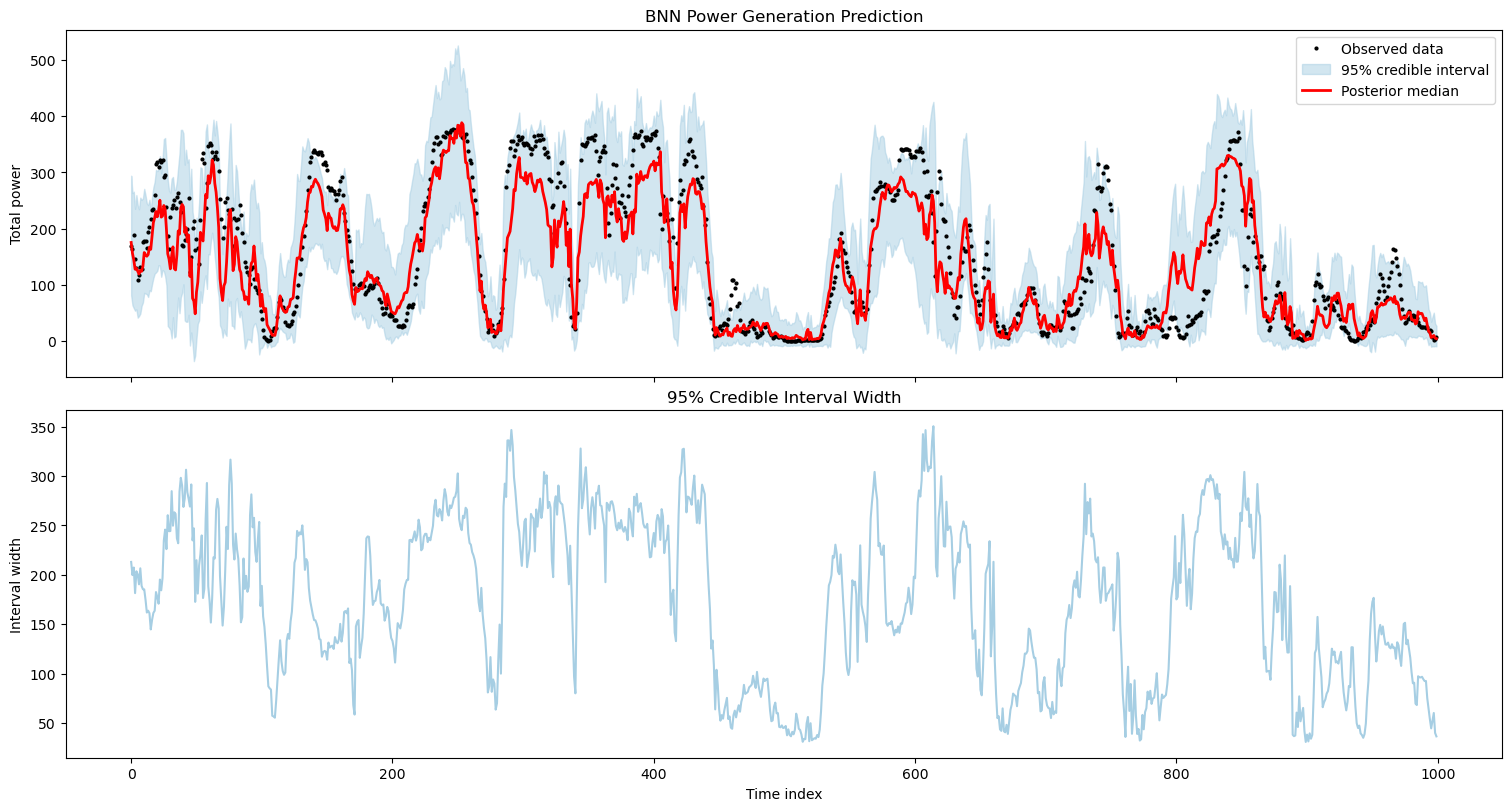

In [126]:
n_plot = 1000

fig, axes = plt.subplots(nrows=2, figsize=(15, 8), sharex=True, constrained_layout=True)

ax = axes[0]
ax.plot(Y_test_gen[:n_plot], ".", color="black", label="Observed data", markersize=4)

ax.fill_between(
    np.arange(n_plot),
    hdis[:n_plot, 0],
    hdis[:n_plot, 1],
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(medians[:n_plot], color="red", label="Posterior median", lw=2)

ax.set(
    ylabel="Total power",
    title="BNN Power Generation Prediction",
)
ax.legend()


# Compute interval width
width = hdis[:n_plot, 1] - hdis[:n_plot, 0]
ax2 = axes[1]
ax2.plot(width, color="#A6CEE3")
ax2.set(
    xlabel="Time index",
    ylabel="Interval width",
    title="95% Credible Interval Width",
)

plt.show()